In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

print("A/B Testing Project Started Successfully!")

A/B Testing Project Started Successfully!


In [2]:
# Number of customers
n_customers = 2000

# Randomly assign each customer to Group A or Group B
groups = np.random.choice(
    ["A", "B"],
    size=n_customers
)

# Display the first 20 group assignments
print(groups[:20])

['B' 'A' 'A' 'A' 'A' 'B' 'A' 'A' 'B' 'B' 'B' 'A' 'B' 'A' 'B' 'B' 'B' 'A'
 'A' 'A']


In [3]:
# Simulate purchase behavior

purchases = []

for group in groups:
    if group == "A":
        purchase = np.random.binomial(1, 0.10)
    else:
        purchase = np.random.binomial(1, 0.14)

    purchases.append(purchase)

# Display the first 20 purchase results
print(purchases[:20])

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0]


In [4]:
# Create the A/B testing dataset

data = pd.DataFrame({
    "customer_id": range(1, n_customers + 1),
    "group": groups,
    "purchased": purchases
})

# Display the first 10 customers
data.head(10)

,customer_id,group,purchased
0,1,B,0
1,2,A,0
2,3,A,0
3,4,A,0
4,5,A,0
5,6,B,0
6,7,A,0
7,8,A,0
8,9,B,0
9,10,B,0


In [5]:
# Check the number of customers in each group

group_counts = data["group"].value_counts()

print("Customers in each group:")
print(group_counts)

Customers in each group:
group
B    1003
A     997
Name: count, dtype: int64


In [6]:
# Count purchases and non-purchases in each group

purchase_counts = pd.crosstab(
    data["group"],
    data["purchased"]
)

print(purchase_counts)

purchased    0    1
group              
A          904   93
B          860  143


In [7]:
# Calculate purchase rate for each group

summary = data.groupby("group")["purchased"].agg(
    customers="count",
    purchases="sum"
)

summary["purchase_rate"] = (
    summary["purchases"] / summary["customers"]
) * 100

print(summary)

       customers  purchases  purchase_rate
group                                     
A            997         93       9.327984
B           1003        143      14.257228


In [8]:
# Compare the purchase rates

rate_A = summary.loc["A", "purchase_rate"]
rate_B = summary.loc["B", "purchase_rate"]

absolute_difference = rate_B - rate_A

relative_improvement = (
    (rate_B - rate_A) / rate_A
) * 100

print(f"Group A purchase rate: {rate_A:.2f}%")
print(f"Group B purchase rate: {rate_B:.2f}%")
print(f"Absolute improvement: {absolute_difference:.2f} percentage points")
print(f"Relative improvement: {relative_improvement:.2f}%")

Group A purchase rate: 9.33%
Group B purchase rate: 14.26%
Absolute improvement: 4.93 percentage points
Relative improvement: 52.84%


## Step 8: Hypothesis Formulation

### Null Hypothesis (H₀)

There is no significant difference in the purchase rates between customers who receive no coupon and customers who receive a 10% discount coupon.

H₀: pA = pB

### Alternative Hypothesis (H₁)

There is a significant difference in the purchase rates between the two groups.

H₁: pA ≠ pB

### Significance Level

α = 0.05

We will reject H₀ if the p-value is less than 0.05.
Otherwise, we will fail to reject H₀.




In [9]:
# Step 9: Perform the two-proportion z-test

conversions = [
    summary.loc["A", "purchases"],
    summary.loc["B", "purchases"]
]

sample_sizes = [
    summary.loc["A", "customers"],
    summary.loc["B", "customers"]
]

z_stat, p_value = proportions_ztest(
    conversions,
    sample_sizes
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

Z-statistic: -3.4166
P-value: 0.000634


In [10]:
# Step 10: Statistical decision

alpha = 0.05

print(f"Significance level: {alpha}")

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("The difference is statistically significant.")
else:
    print("Fail to reject the null hypothesis.")
    print("The difference is not statistically significant.")

Significance level: 0.05
Reject the null hypothesis.
The difference is statistically significant.


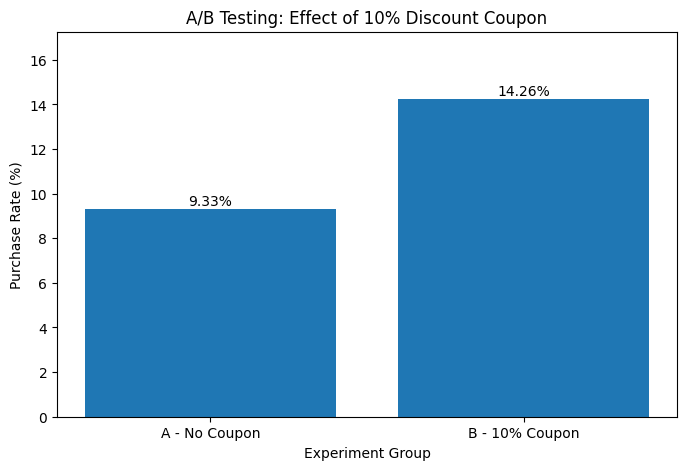

In [21]:
# Step 11: Visualize purchase rates

groups = ["A - No Coupon", "B - 10% Coupon"]

purchase_rates = [
    summary.loc["A", "purchase_rate"],
    summary.loc["B", "purchase_rate"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(groups, purchase_rates)

plt.ylabel("Purchase Rate (%)")
plt.xlabel("Experiment Group")
plt.title("A/B Testing: Effect of 10% Discount Coupon")

# Display values on top of the bars
for bar, rate in zip(bars, purchase_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.2f}%",
        ha="center",
        va="bottom"
    )

plt.ylim(0, max(purchase_rates) + 3)
plt.show()

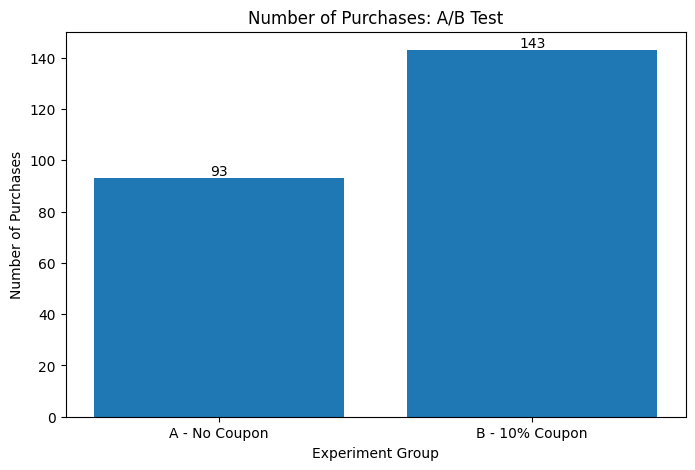

In [26]:
# Step 12: Compare the number of purchases

groups = ["A - No Coupon", "B - 10% Coupon"]

purchases = [
    summary.loc["A", "purchases"],
    summary.loc["B", "purchases"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(groups, purchases)

plt.ylabel("Number of Purchases")
plt.xlabel("Experiment Group")
plt.title("Number of Purchases: A/B Test")

# Display values on top of bars
for bar, value in zip(bars, purchases):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.show()

In [29]:
# Step 13: Final results table

results = pd.DataFrame({
    "Metric": [
        "Customers",
        "Purchases",
        "Purchase Rate",
        "Absolute Improvement"
    ],
    "Group A - No Coupon": [
        summary.loc["A", "customers"],
        summary.loc["A", "purchases"],
        f"{summary.loc['A', 'purchase_rate']:.2f}%",
        "-"
    ],
    "Group B - 10% Coupon": [
        summary.loc["B", "customers"],
        summary.loc["B", "purchases"],
        f"{summary.loc['B', 'purchase_rate']:.2f}%",
        f"{absolute_difference:.2f} percentage points"
    ]
})

results

,Metric,Group A - No Coupon,Group B - 10% Coupon
0,Customers,997,1003
1,Purchases,93,143
2,Purchase Rate,9.33%,14.26%
3,Absolute Improvement,-,4.93 percentage points


In [14]:
# Step 14: Statistical test results

statistical_results = pd.DataFrame({
    "Statistical Measure": [
        "Significance Level",
        "Z-statistic",
        "P-value",
        "Decision"
    ],
    "Value": [
        alpha,
        round(z_stat, 4),
        round(p_value, 6),
        "Reject H₀" if p_value < alpha else "Fail to reject H₀"
    ]
})

statistical_results

,Statistical Measure,Value
0,Significance Level,0.05
1,Z-statistic,-3.4166
2,P-value,0.000634
3,Decision,Reject H₀
